# TITANIC
## The rule in the data: what a model learns from a historical decision

**Question:** Survival on the Titanic was shaped by a human rule (women and children first), applied unevenly by class and by side of the ship. What does a model learn when trained on that record, and would a people-analytics audit catch it?

This is a historical observational case study, not a rescue-prioritization system. No individual simulation or causal claim is offered.

### Decision log / public data, bounded scope

- Source: committed `data/passengers.csv`, a minimal extract of titanic3. Data obtained from http://hbiostat.org/data courtesy of the Vanderbilt University Department of Biostatistics.
- Coverage: **1,309 passengers**; crew are not included. The 891-row Kaggle sample is a regression test.
- Level: standard EDA plus association discovery and prespecified predictive analysis.
- Protocol: seed 20261014, committed ticket-grouped split and five training folds. 1,048 training records, 261 held out, plus 20 x 5 repeated grouped folds for the audit. No tuning on the test set.
- Fare is divided by ticket size (FarePerPerson). Original names, tickets and cabin strings are not loaded; group labels and IDs are never predictors.
- Every analytical computation below calls reusable code in `Python/`.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'data' / 'passengers.csv').exists():
    root = root.parent
sys.path.insert(0, str(root))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from Python.analysis import load_data, missingness, run_analysis, MODELS
from Python.figures import eda_figure
pd.set_option('display.max_columns', 20)
data = load_data(root)
print(f'{len(data):,} records | {data.PassengerId.nunique():,} unique passenger IDs')
display(data.drop(columns=['ticket_group']).head())
display(data.groupby('subset').Survived.agg(['size', 'sum', 'mean']))

1,309 records | 1,309 unique passenger IDs


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,TicketSize,FarePerPerson,Embarked,Title,BoatSide,InKaggleTrain,subset,cv_fold
0,1,1,1,female,29.00,0,0,211.3375,4,52.834375,S,Miss,Port,1,test,-1
1,2,1,1,male,0.92,1,2,151.5500,6,25.258333,S,Master,Starboard,1,train,2
2,3,0,1,female,2.00,1,2,151.5500,6,25.258333,S,Miss,None recorded,1,train,2
3,4,0,1,male,30.00,1,2,151.5500,6,25.258333,S,Mr,None recorded,0,train,2
4,5,0,1,female,25.00,1,2,151.5500,6,25.258333,S,Mrs,None recorded,1,train,2


,size,sum,mean
subset,,,
test,261,100,0.383142
train,1048,400,0.381679


## 01 / First understand what was recorded

Missing ages are retained as unknown in association baskets and imputed only within model-training partitions. Fare and age distributions are not symmetric. Missing records and the labeled-sample selection constrain interpretation; outliers are not automatically errors.

In [2]:
display(missingness(data))
print('Exact duplicate records:', data.duplicated().sum())
display(data[['Age', 'FarePerPerson', 'SibSp', 'Parch']].describe())
display(data[['Pclass', 'Age', 'FarePerPerson', 'SibSp', 'Parch', 'Survived']].corr(method='spearman'))
figure = eda_figure(data)
display(figure)
plt.close(figure)

,field,n_missing,pct_missing
0,PassengerId,0,0.000000
1,Survived,0,0.000000
2,Pclass,0,0.000000
3,Sex,0,0.000000
4,Age,263,0.200917
5,SibSp,0,0.000000
6,Parch,0,0.000000
7,Fare,1,0.000764
8,TicketSize,0,0.000000
9,FarePerPerson,1,0.000764


Exact duplicate records: 0


,Age,FarePerPerson,SibSp,Parch
count,1046.000000,1308.000000,1309.000000,1309.000000
mean,29.881138,14.757627,0.498854,0.385027
std,14.413493,13.555638,1.041658,0.865560
min,0.170000,0.000000,0.000000,0.000000
25%,21.000000,7.550000,0.000000,0.000000
50%,28.000000,8.050000,0.000000,0.000000
75%,39.000000,15.008325,1.000000,0.000000
max,80.000000,128.082300,8.000000,9.000000


,Pclass,Age,FarePerPerson,SibSp,Parch,Survived
Pclass,1.000000,-0.395892,-0.831839,-0.066679,-0.028752,-0.309734
Age,-0.395892,1.000000,0.422470,-0.129929,-0.216097,-0.041672
FarePerPerson,-0.831839,0.422470,1.000000,-0.048954,-0.177480,0.241491
SibSp,-0.066679,-0.129929,-0.048954,1.000000,0.438373,0.083620
Parch,-0.028752,-0.216097,-0.177480,0.438373,1.000000,0.162086
Survived,-0.309734,-0.041672,0.241491,0.083620,0.162086,1.000000


<Figure size 1200x800 with 4 Axes>

## 02 / Describe uncertainty before predicting

Within each sex-by-class group, start with Beta(1,1), add observed survived and non-survived counts, and calculate the exact central 95% beta credible interval.            These summaries use **all 1,309 records** and are separate from predictive evaluation. They describe this selected sample, not causal sex or class effects in a population.

In [3]:
data, tables, summary = run_analysis(root)
display(tables['bayesian_rates'])
print('Survived:', summary['survived'], 'of', summary['n'])

,sex,pclass,n,survived,observed_rate,posterior_mean,lower,upper,prior_alpha,prior_beta
0,female,1,144,139,0.965278,0.958904,0.921365,0.984665,1,1
1,female,2,106,94,0.886792,0.879630,0.812291,0.933696,1,1
2,female,3,216,106,0.490741,0.490826,0.424760,0.557051,1,1
3,male,1,179,61,0.340782,0.342541,0.275340,0.413039,1,1
4,male,2,171,25,0.146199,0.150289,0.101183,0.207044,1,1
5,male,3,493,75,0.152130,0.153535,0.123169,0.186552,1,1


Survived: 500 of 1309


## 03 / Discover transparent training-only associations

Apriori considers itemsets of at most three items, with survival only as a singleton consequent. Support ≥ .04, confidence ≥ .60, joint count ≥ 20 and lift ≥ 1 are fixed exploratory filters. For each rule we show counts and its training-population outcome baseline. A high lift is an association, not a significance test, causal explanation or an individual prediction.

In [4]:
print('Retained rules:', len(tables['rules']))
display(tables['rules'].head(12))

Retained rules: 45


,antecedent,consequent,support,confidence,lift,count,antecedent_count,consequent_count,baseline,N
0,Fare=High (>30) & Sex=female,Outcome=Survived,0.046756,0.960784,2.517255,49,51,400,0.381679,1048
1,Class=1 & Sex=female,Outcome=Survived,0.097328,0.953271,2.497570,102,107,400,0.381679,1048
2,Fare=Middle (10-30) & Sex=female,Outcome=Survived,0.104008,0.886179,2.321789,109,123,400,0.381679,1048
3,Class=2 & Sex=female,Outcome=Survived,0.076336,0.879121,2.303297,80,91,400,0.381679,1048
4,Age=Child (<16) & Family=2-4,Outcome=Survived,0.045802,0.786885,2.061639,48,61,400,0.381679,1048
5,Family=2-4 & Sex=female,Outcome=Survived,0.139313,0.776596,2.034681,146,188,400,0.381679,1048
6,Age=Adult (16-59) & Sex=female,Outcome=Survived,0.180344,0.762097,1.996694,189,248,400,0.381679,1048
7,Family=Alone & Sex=female,Outcome=Survived,0.104962,0.753425,1.973973,110,146,400,0.381679,1048
8,Sex=female,Outcome=Survived,0.254771,0.729508,1.911311,267,366,400,0.381679,1048
9,Class=1 & Family=2-4,Outcome=Survived,0.080153,0.700000,1.834000,84,120,400,0.381679,1048


## 04 / An honest comparison: grouped validation, then an untouched holdout

All three models use the same committed five folds. Each fold relearns age/fare medians, alphabetically tie-broken embarkation mode and continuous-feature sample-SD scaling. The prevalence baseline also refits inside each fold.

The random forest uses 500 trees, max_features=3, min_samples_leaf=5, seed 20261014, two workers and no tuning. Bayesian logistic uses independent Normal(0,5²) intercept and Normal(0,2.5²) coefficient priors. Test predictions are posterior-mode plug-ins, not integrated posterior predictions.

ROC event = survived; no ROC reversal. Balanced accuracy uses probability ≥ .5. Lower Brier and log loss are better. Fold SD is descriptive variability, not a confidence interval.

roc_auc               brier            log_loss  \
                         mean       std      mean       std      mean   
model                                                                   
Bayesian logistic    0.829332  0.026815  0.154517  0.008095  0.481360   
Prevalence baseline  0.500000  0.000000  0.236001  0.000236  0.664882   
Random forest        0.843694  0.020514  0.146650  0.003525  0.463999   

                              balanced_accuracy            
                          std              mean       std  
model                                                      
Bayesian logistic    0.025908          0.764100  0.022324  
Prevalence baseline  0.000482          0.500000  0.000000  
Random forest        0.015856          0.756257  0.017087

,phase,fold,model,roc_auc,brier,log_loss,balanced_accuracy,n
15,test,-1,Prevalence baseline,0.500000,0.236346,0.665586,0.500000,261
16,test,-1,Random forest,0.874255,0.126598,0.412818,0.797205,261
17,test,-1,Bayesian logistic,0.865870,0.131032,0.419653,0.791677,261


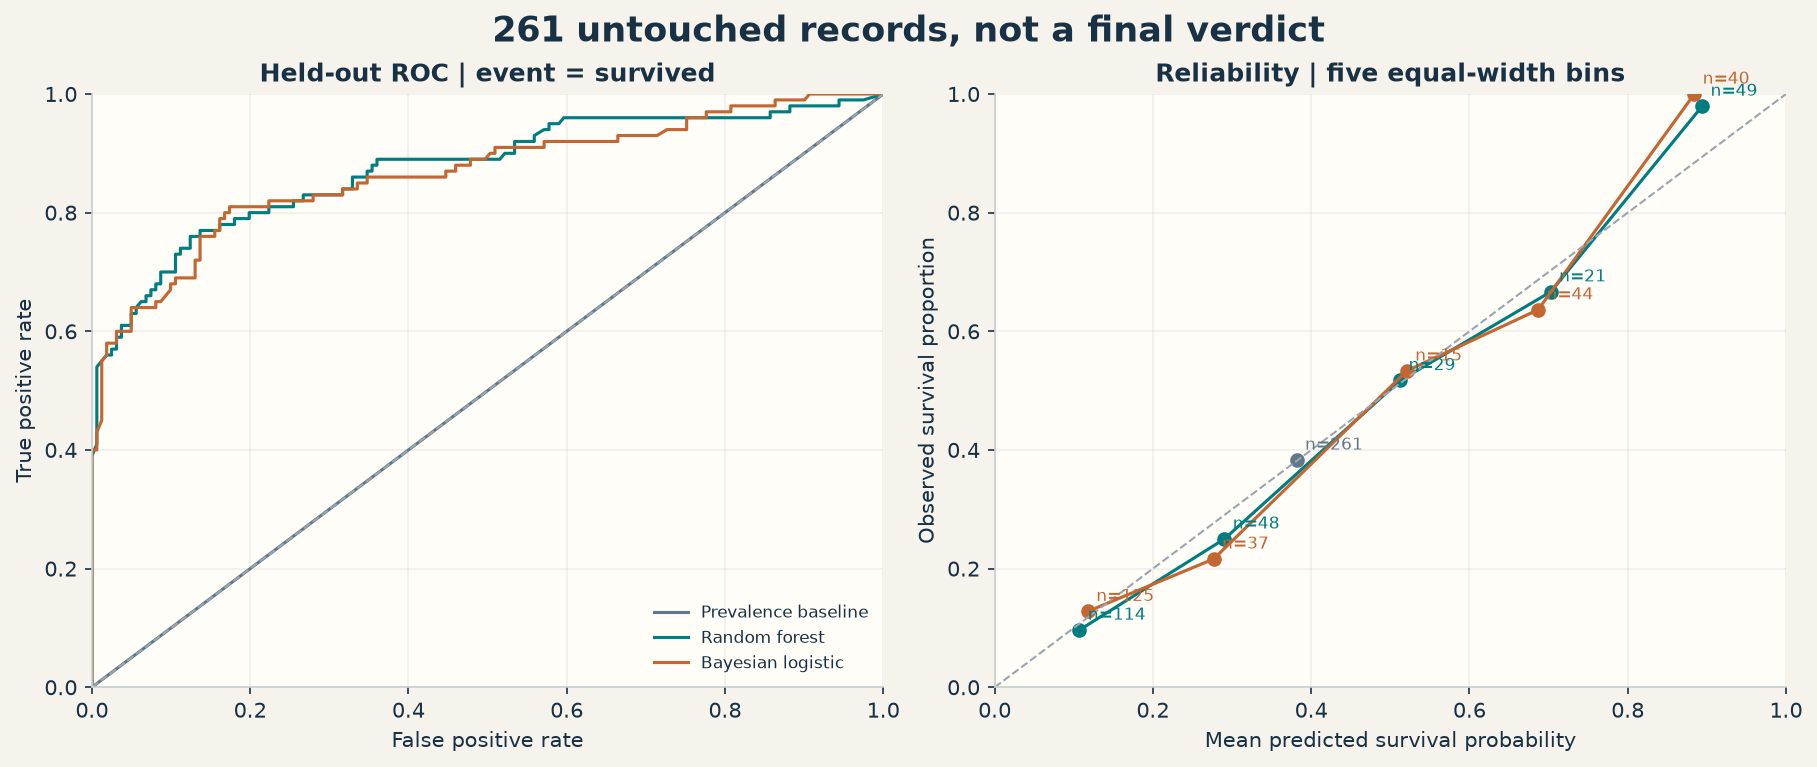

,model,bin,n,predicted,observed
0,Prevalence baseline,"[0,0.2]",0,NaN,NaN
1,Prevalence baseline,"(0.2,0.4]",261,0.381679,0.383142
2,Prevalence baseline,"(0.4,0.6]",0,NaN,NaN
3,Prevalence baseline,"(0.6,0.8]",0,NaN,NaN
4,Prevalence baseline,"(0.8,1]",0,NaN,NaN
5,Random forest,"[0,0.2]",114,0.107134,0.096491
6,Random forest,"(0.2,0.4]",48,0.290326,0.250000
7,Random forest,"(0.4,0.6]",29,0.512552,0.517241
8,Random forest,"(0.6,0.8]",21,0.702793,0.666667
9,Random forest,"(0.8,1]",49,0.894115,0.979592


In [5]:
display(tables['metrics'].query("phase == 'cv'").groupby('model')[['roc_auc', 'brier', 'log_loss', 'balanced_accuracy']].agg(['mean', 'std']))
display(tables['metrics'].query("phase == 'test'"))
display(Image(filename=str(root / 'outputs' / 'python' / 'roc_calibration.png')))
display(tables['calibration'])

## 05 / Bayesian effects: uncertainty is part of the result

The inverse analytic negative-log-posterior Hessian provides the local Laplace covariance. Displayed intervals are **approximate marginal 95% credible intervals**, not exact intervals or MCMC output. Continuous effects are per one training sample SD (fare is log1p transformed). Reference levels are female, first class and embarkation at C. Odds ratios are not risk ratios. The coefficient intervals do not include model-selection or dataset-selection uncertainty.

,term,estimate,sd,lower,upper,odds_ratio,or_lower,or_upper,prior_sd
0,intercept,2.634934,0.309517,2.028291,3.241576,13.942386,7.601086,25.573995,5.0
1,age_z,-0.426510,0.090083,-0.603069,-0.249952,0.652783,0.547130,0.778838,2.5
2,log_fare_z,0.029738,0.129742,-0.224552,0.284029,1.030185,0.798874,1.328472,2.5
3,family_size_z,-0.241041,0.088854,-0.415191,-0.066891,0.785809,0.660214,0.935297,2.5
4,age_missing,-0.304049,0.224510,-0.744080,0.135981,0.737824,0.475171,1.145661,2.5
5,sex_male,-2.582753,0.176291,-2.928277,-2.237229,0.075566,0.053489,0.106754,2.5
6,class_2,-0.878955,0.284672,-1.436902,-0.321008,0.415217,0.237663,0.725418,2.5
7,class_3,-1.780906,0.321519,-2.411071,-1.150740,0.168485,0.089719,0.316402,2.5
8,embarked_Q,-0.281467,0.337813,-0.943567,0.380633,0.754676,0.389237,1.463211,2.5
9,embarked_S,-0.524374,0.208306,-0.932647,-0.116101,0.591926,0.393511,0.890385,2.5


Posterior max absolute gradient: 2.356694440291962e-11
Optimizer: Optimization terminated successfully.


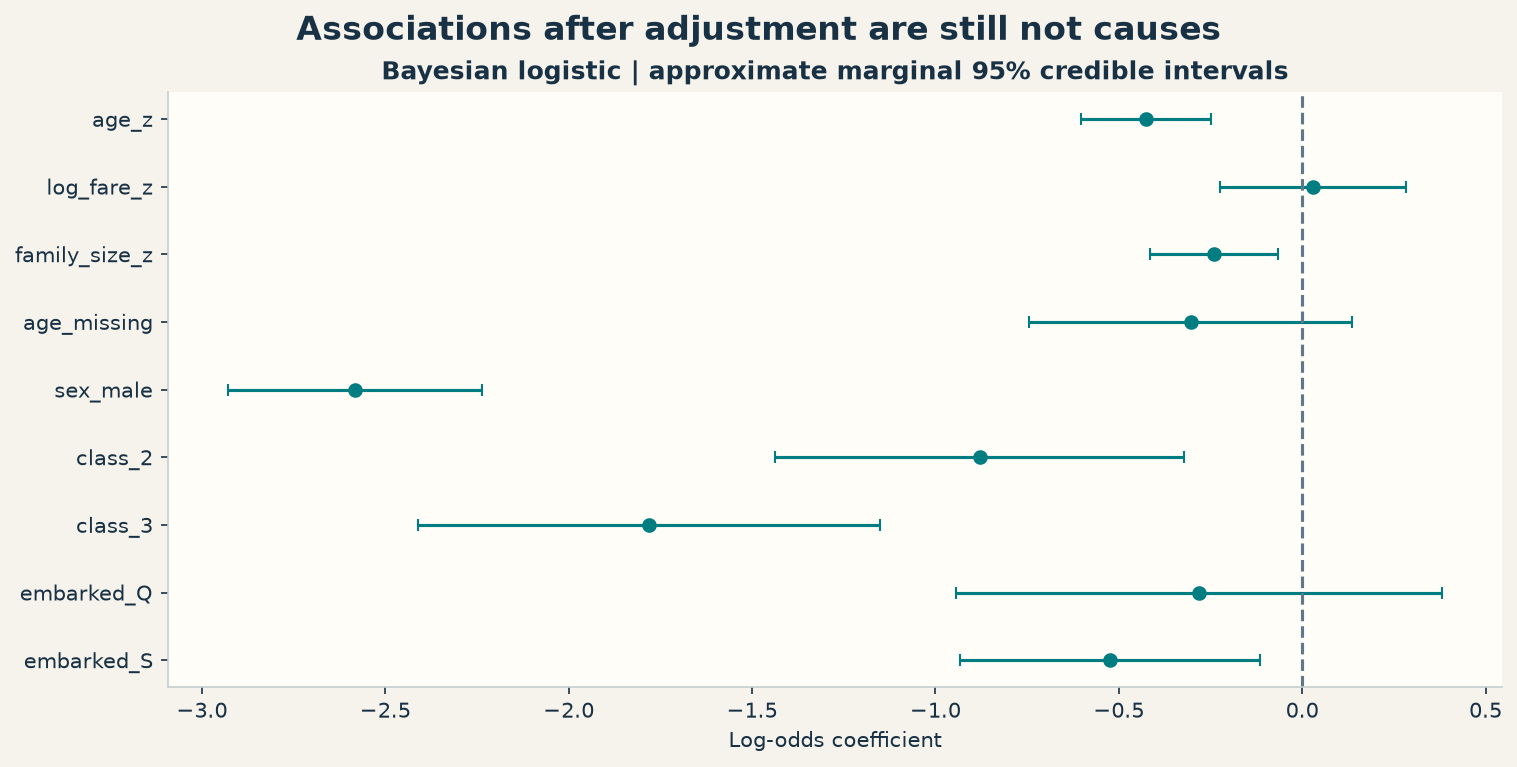

In [6]:
display(tables['coefficients'])
print('Posterior max absolute gradient:', summary['bayesian_max_abs_gradient'])
print('Optimizer:', summary['bayesian_optimizer_message'])
display(Image(filename=str(root / 'outputs' / 'python' / 'bayesian_effects.png')))

## 07 / The rule and the ship

Women and children vs men by class, sensitivity to the child cutoff, the side of the ship each lifeboat was launched from, and where ages are missing. All proportions carry Wilson 95% intervals. Boat side is descriptive only and never a predictor.

In [7]:
for name in ['policy_groups', 'child_cutoffs', 'boat_side', 'missing_age']:
    print(name)
    display(tables[name])

policy_groups


,group,pclass,n,survived,rate,lower,upper
0,Women and children,All,525,368,0.700952,0.660444,0.738541
1,Men,All,784,132,0.168367,0.143805,0.196163
2,Women and children,1,149,144,0.966443,0.923856,0.985583
3,Men,1,174,56,0.321839,0.256918,0.394457
4,Women and children,2,118,105,0.889831,0.820603,0.934477
5,Men,2,159,14,0.088050,0.053174,0.142363
6,Women and children,3,258,119,0.461240,0.401427,0.522191
7,Men,3,451,62,0.137472,0.108741,0.172327


child_cutoffs


,cutoff,pclass,n,survived,rate,lower,upper
0,12,All,91,51,0.560440,0.458071,0.657912
1,12,1,5,4,0.800000,0.375535,0.963776
2,12,2,22,22,1.000000,0.851345,1.000000
3,12,3,64,25,0.390625,0.280556,0.513081
4,14,All,99,57,0.575758,0.477367,0.668489
5,14,1,6,5,0.833333,0.436497,0.969947
6,14,2,25,25,1.000000,0.866808,1.000000
7,14,3,68,27,0.397059,0.289287,0.515839
8,16,All,115,66,0.573913,0.482585,0.660463
9,16,1,8,7,0.875000,0.529112,0.977583


boat_side


,side,n,lower,upper,adult_men,adult_men_share
0,Starboard,261,0.352020,0.470515,107,0.409962
1,Port,221,0.085338,0.171917,27,0.122172
2,Unknown,4,0.045587,0.699358,1,0.250000


missing_age


,pclass,n,lower,upper,missing_age,missing_share
0,All,1309,0.180100,0.223484,263,0.200917
1,1,323,0.089597,0.160805,39,0.120743
2,2,277,0.035864,0.091758,16,0.057762
3,3,709,0.261042,0.327927,208,0.293371


## 08 / What does a model learn? Repeated grouped CV with paired intervals

Policy-only, structure-only and combined Laplace logistic models, plus sex-blind and sex-blind + title variants and a random-forest benchmark, all scored on the same 20 x 5 ticket-grouped folds. Differences vs the reference (Policy + structure) use Nadeau-Bengio corrected t intervals.

In [8]:
display(tables['policy_fit'])
display(tables['model_comparison'].query("metric == 'roc_auc'")[['model', 'mean_model', 'mean_difference', 'lower', 'upper']])

,model,terms,loglik,mcfadden_r2
0,Policy only,4,-664.678396,0.236451
1,Structure only,6,-792.439045,0.089686
2,Policy + structure,13,-558.880206,0.357987
3,Sex-blind,9,-765.448143,0.120692
4,Sex-blind + title,13,-574.129168,0.340470


,model,mean_model,mean_difference,lower,upper
2,Prevalence baseline,0.500000,-0.355181,-0.381690,-0.328671
5,Policy only,0.791050,-0.064131,-0.080311,-0.047951
8,Structure only,0.691201,-0.163980,-0.198831,-0.129128
11,Policy + structure,0.855181,0.000000,0.000000,0.000000
14,Sex-blind,0.705764,-0.149417,-0.180268,-0.118565
17,Sex-blind + title,0.846617,-0.008564,-0.019781,0.002653
20,Random forest,0.855878,0.000698,-0.012808,0.014203


## 09 / Remove the attribute, keep the bias

Dropping sex terms removes most of the predicted sex gap, but adding title (Mr/Mrs/Miss/Master) brings it back: title is a near-perfect proxy for recorded sex. Then an HR-style audit on out-of-fold probabilities: impact ratios (context: the four-fifths heuristic), calibration and error rates per group, with cells below 20 suppressed.

In [9]:
display(tables['proxy_gap'])
display(tables['sex_recovery'])
display(tables['fairness_audit'][['grouping', 'group', 'n', 'base_rate', 'mean_predicted', 'selection_rate', 'impact_ratio', 'ir_lower', 'ir_upper', 'tpr', 'fpr', 'ppv']])

,source,female_mean,male_mean,gap,share_of_observed_gap
0,Observed outcomes,0.727468,0.190985,0.536483,1.000000
1,Policy + structure,0.724672,0.191457,0.533215,0.993908
2,Sex-blind,0.429320,0.356136,0.073184,0.136415
3,Sex-blind + title,0.720047,0.194801,0.525246,0.979054


,features,mean_auc,sd_auc,min_auc,max_auc,folds
0,Without title,0.698280,0.025708,0.633155,0.745216,100
1,With title,0.999906,0.000141,0.999265,1.000000,100


,grouping,group,n,base_rate,mean_predicted,selection_rate,impact_ratio,ir_lower,ir_upper,tpr,fpr,ppv
0,Sex,Female,466,0.727468,0.724672,0.809013,1.000000,0.939519,1.064374,0.899705,0.566929,0.809019
1,Sex,Male,843,0.190985,0.191457,0.028470,0.035191,0.023665,0.052331,0.124224,0.005865,0.833333
2,Class,Class 1,323,0.619195,0.616394,0.461300,1.000000,0.846483,1.181358,0.720000,0.040650,0.966443
3,Class,Class 2,277,0.429603,0.429261,0.425993,0.923461,0.770965,1.106121,0.882353,0.082278,0.889831
4,Class,Class 3,709,0.255289,0.255424,0.188999,0.409708,0.337894,0.496785,0.419890,0.109848,0.567164
5,Sex x class,Female / class 1,144,0.965278,0.951320,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.965278
6,Sex x class,Female / class 2,106,0.886792,0.887290,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.886792
7,Sex x class,Female / class 3,216,0.490741,0.493771,0.587963,0.587963,0.525855,0.657407,0.679245,0.500000,0.566929
8,Sex x class,Male / class 1,179,0.340782,0.346957,0.027933,0.027933,0.011771,0.066287,0.081967,0.000000,NaN
9,Sex x class,Male / class 2,171,0.146199,0.145337,0.070175,0.070175,0.040667,0.121095,0.440000,0.006849,NaN


## 10 / If this were promotion data: a synthetic check with known truth

5,000 **synthetic** employees with an injected -0.70 log-odds penalty for women, -0.50 for regional staff and no part-time effect. A gender-visible model recovers the penalty; a gender-blind model moves it onto part-time work, a proxy with no true effect.

In [10]:
display(tables['sim_coefficients'])
display(tables['sim_gap'])
display(tables['sim_recovery'])
display(tables['sim_impact'])

,model,term,estimate,sd,lower,upper,odds_ratio,injected
0,Gender visible,intercept,-1.452976,0.077757,-1.605377,-1.300576,0.233873,NaN
1,Gender visible,rating_z,1.050155,0.057053,0.938334,1.161976,2.858094,NaN
2,Gender visible,tenure_z,0.142864,0.048095,0.048600,0.237128,1.153573,NaN
3,Gender visible,woman,-0.676744,0.108077,-0.888571,-0.464917,0.508269,-0.7
4,Gender visible,regional,-0.633774,0.109889,-0.849153,-0.418394,0.530586,-0.5
5,Gender visible,part_time,0.016335,0.148440,-0.274602,0.307271,1.016469,0.0
6,Gender-blind,intercept,-1.714575,0.068437,-1.848710,-1.580441,0.180040,NaN
7,Gender-blind,rating_z,1.041724,0.056547,0.930893,1.152554,2.834097,NaN
8,Gender-blind,tenure_z,0.129111,0.047661,0.035697,0.222524,1.137816,NaN
9,Gender-blind,regional,-0.592759,0.108578,-0.805568,-0.379950,0.552800,-0.5


,source,women_mean,men_mean,gap
0,Historical decisions,0.122126,0.235437,-0.113310
1,Merit-only counterfactual,0.221264,0.254854,-0.033590
2,Gender visible,0.125157,0.199096,-0.073939
3,Gender-blind,0.161342,0.165203,-0.003862


,target,features,test_auc,test_n
0,Woman,"Rating, tenure, site, part-time",0.622993,1520


,label,grouping,group,n,promoted,rate,lower,upper,reference,impact_ratio,ir_lower,ir_upper
0,Historical decisions,Gender,Man,2590,554,0.213900,0.198537,0.230110,Man,1.000000,0.900855,1.110057
1,Historical decisions,Gender,Woman,2410,299,0.124066,0.111500,0.137829,Man,0.580022,0.509698,0.660047
2,Historical decisions,Site,Headquarters,3194,624,0.195366,0.181986,0.209479,Headquarters,1.000000,0.905259,1.104656
3,Historical decisions,Site,Regional,1806,229,0.126800,0.112241,0.142942,Headquarters,0.649035,0.564241,0.746571
4,Merit-only counterfactual,Gender,Man,2590,611,0.235907,0.219955,0.252642,Man,1.000000,0.906631,1.102985
5,Merit-only counterfactual,Gender,Woman,2410,559,0.231950,0.215534,0.249220,Man,0.983226,0.889296,1.087078
6,Merit-only counterfactual,Site,Headquarters,3194,771,0.241390,0.226866,0.256536,Headquarters,1.000000,0.916727,1.090837
7,Merit-only counterfactual,Site,Regional,1806,399,0.220930,0.202400,0.240645,Headquarters,0.915241,0.823019,1.017798


## 11 / A story with limits, not a leaderboard

The descriptive sex/class differences, rule associations and adjusted model coefficients answer different questions. They need not agree in magnitude. The small held-out sample and dependent historical records make score differences uncertain: no universal winner or statistically significant gain is claimed. Random-forest predictions may differ across R and Python, whereas the committed design matrices and Bayesian objective should match numerically.

**Fairness and selection:** historically recorded sex and class are not grounds for discriminatory decisions. Curated labeled records are not a random sample of a modern deployment population. Ticket groups imperfectly approximate family/social dependence. Unknown ages, incomplete records and correlated predictors limit generalization. These results cannot determine why an individual survived and must not support rescue recommendations.

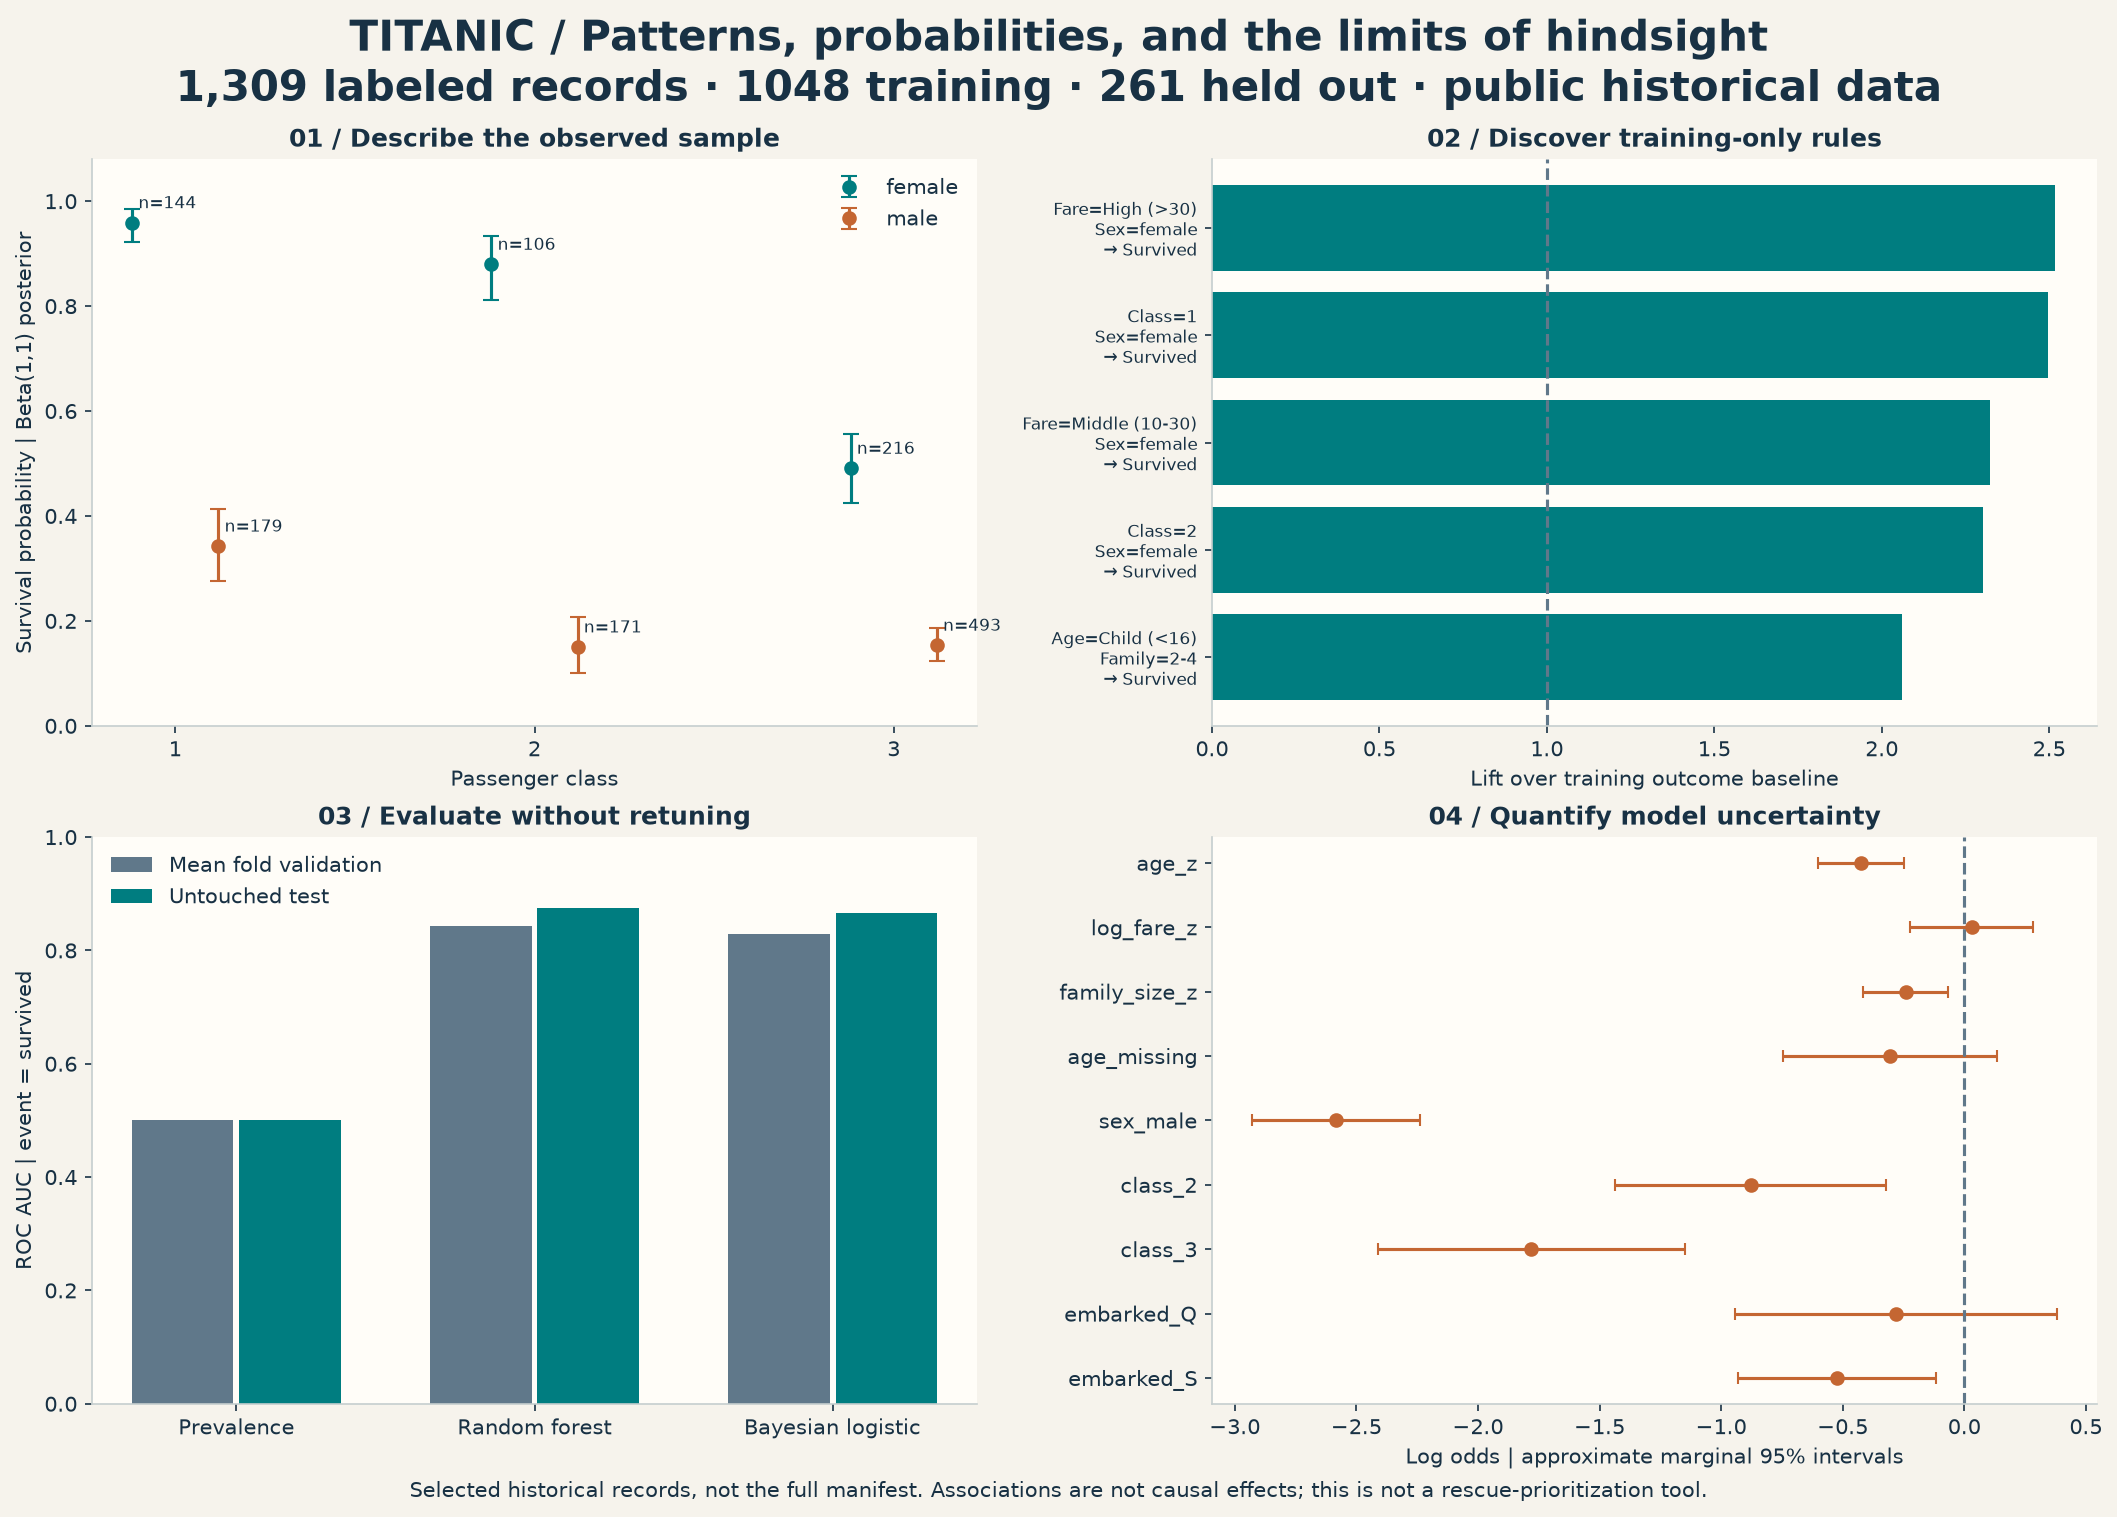

seed                                                                   20261014
n                                                                          1309
train_n                                                                    1048
test_n                                                                      261
survived                                                                    500
rule_count                                                                   45
bayesian_max_abs_gradient                                                   0.0
bayesian_optimizer_success                                                 True
bayesian_optimizer_message                Optimization terminated successfully.
prediction_type               Posterior-mode plug-in; Laplace marginal coeff...
coverage                        1,309 titanic3 passenger records; crew excluded
Name: Reproducibility summary, dtype: object

In [11]:
display(Image(filename=str(root / 'outputs' / 'python' / 'overview.png')))
display(pd.Series(summary, name='Reproducibility summary'))